<a href="https://colab.research.google.com/github/spbromberg/ds2002-fa26/blob/main/notebooks/07-visualization/2026-11-11%20%E2%80%94%20Critique%20and%20Redesign%20%E2%80%94%20Studio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Critique and Redesign

**Studio — 2026-11-11 · Fall 2026**

---

## From Monday's cookbook to a graded chart

Monday's **Visualization for Decisions** notebook is a recipe book: sorted bars, labeled lines, `finish()`, and titles computed from the data. Today you run the **six-point rubric** on purposefully bad charts, rebuild them twice (mechanics first, then argument), and apply the same lens to your midterm work.

**Lab 11** uses the *same* sample data and the same rubric. It is due **Wednesday, November 18, 11:59pm ET** so you can finish midterm presentations first. If you have not opened Monday's notebook since then, skim the cheat sheet at the end before you start the studio charts.

### Monday's four rules meet the rubric

The presentation rubric is how we grade. Monday's four rules are how you fix charts before they hit a slide.

| Monday rule | Rubric criteria it mainly hits |
|---|---|
| One chart, one message | Title states a finding; no wasted ink |
| Title states the finding | Title states a finding |
| Label axes and name the unit | Axes labeled with units |
| Sort by value (unless time) | Readable; often honest scale |
| Pick the right chart type | Right chart for the question |
| Truncated bars, raw counts, overplotting | Honest scale; readable |

Run the setup cell next. It defines `score()` (the rubric) and `finish()` (the same helper from Monday).

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()

print('ready')

ready


### The six-point rubric

Score any chart out of 6. This is the same rubric used on both project presentations and Lab 11.

| # | Criterion | Fails when |
|---|---|---|
| 1 | Title states a finding | Title names the columns |
| 2 | Axes labeled with units | "Revenue" with no currency; no axis label |
| 3 | Right chart for the question | Pie for comparison; bars for a trend |
| 4 | Honest scale | Truncated bar axis; unnormalized comparison |
| 5 | Readable | Overlapping labels, clipped text, unsorted categories |
| 6 | No wasted ink | Decoration, redundant legends, chart junk |

Before you call a chart done, also run Monday's four questions: what one sentence does it prove; is that the title; are units obvious; is anything on the page not carrying information?

### Chart 1 — the pie chart

Same categories as Monday's worked example. Pie charts are not on the chart-picker list for a reason.

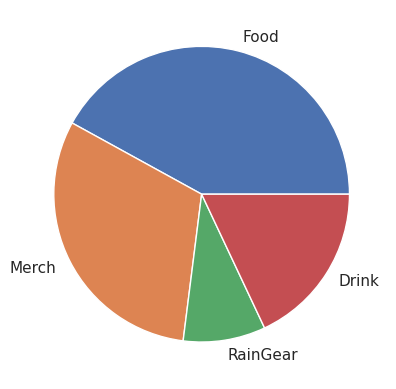

In [2]:
cats = ['Food', 'Merch', 'RainGear', 'Drink']
vals = [4200, 3100, 900, 1800]
plt.pie(vals, labels=cats)
plt.show()

**TODO:** score it with `score(...)`. Then say in a comment which two slices you cannot rank by eye — that is the concrete cost of the chart type.

In [4]:
score(
    title=False,
    axes=False,
    chart_type=False,
    scale=True,
    readable=True,
    ink=True
)

# Drink and RainGear are hardest to rank by eye: comparing pie-slice angles
# is less precise than comparing bar lengths.

FAIL - title states a finding
FAIL - axes labeled with units
FAIL - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 3/6


3

**Iteration 1 — fix the mechanics (Monday Recipe 1).**

**TODO:** rebuild as a sorted horizontal bar on `fig, ax`. Use `finish()` with a title that states a finding, `revenue (USD)` on the axis, `ax.bar_label` for the dollar amounts, and `BLUE` bars. Do not worry yet whether the message is the *best* one available.

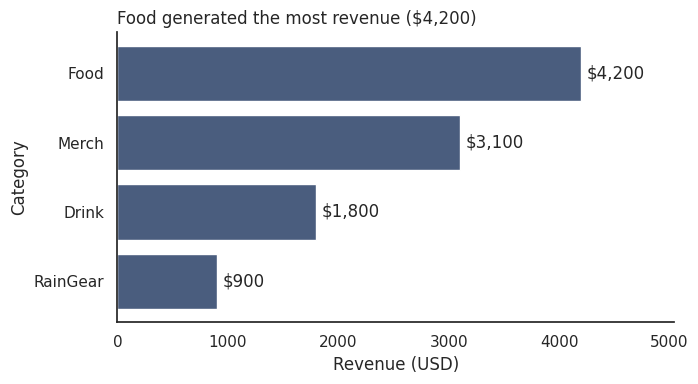

In [5]:
revenue = pd.Series(vals, index=cats, name='revenue')
ordered = revenue.sort_values(ascending=True)
top_category = revenue.idxmax()
top_value = revenue.max()

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(ordered.index, ordered.values, color=BLUE)

finish(
    ax,
    f'{top_category} generated the most revenue (${top_value:,.0f})',
    xlabel='Revenue (USD)',
    ylabel='Category'
)

ax.bar_label(bars, labels=[f'${value:,.0f}' for value in ordered.values], padding=4)
ax.set_xlim(0, ordered.max() * 1.2)
plt.show()


**Iteration 2 — sharpen the argument (Monday Recipe 2).**

A sorted bar of totals probably says food leads revenue. True, and not very useful.

**TODO:** rain gear is tiny in total but strong when it actually sells. Chart `revenue_per_game` below: highlight RainGear in `RUST`, grey the rest, and write a title that states *that* finding.

In [6]:
detail = pd.DataFrame({
    'category': ['Food', 'Merch', 'RainGear', 'Drink'],
    'revenue': [4200, 3100, 900, 1800],
    'games_sold_in': [6, 6, 2, 6],   # rain gear only moves on wet days
}).set_index('category')
detail['revenue_per_game'] = detail['revenue'] / detail['games_sold_in']
detail

,revenue,games_sold_in,revenue_per_game
category,,,
Food,4200,6,700.000000
Merch,3100,6,516.666667
RainGear,900,2,450.000000
Drink,1800,6,300.000000


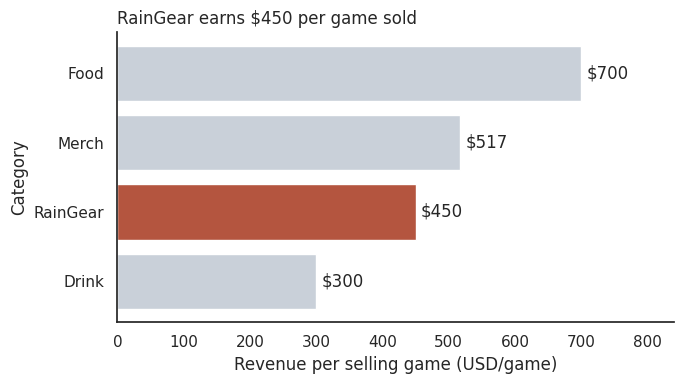

In [7]:
ordered = detail['revenue_per_game'].sort_values(ascending=True)
colors = [RUST if category == 'RainGear' else GRAY for category in ordered.index]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(ordered.index, ordered.values, color=colors)

finish(
    ax,
    f"RainGear earns ${detail.loc['RainGear', 'revenue_per_game']:,.0f} per game sold",
    xlabel='Revenue per selling game (USD/game)',
    ylabel='Category'
)

ax.bar_label(bars, labels=[f'${value:,.0f}' for value in ordered.values], padding=4)
ax.set_xlim(0, ordered.max() * 1.2)
plt.show()

### Chart 2 — truncated axis (Monday mistake #1)

**TODO:** score this chart, name the specific problem, rebuild with the y-axis starting at zero, and use `finish()` with an honest title — including if the honest answer is "these zones are within a few percent of each other."

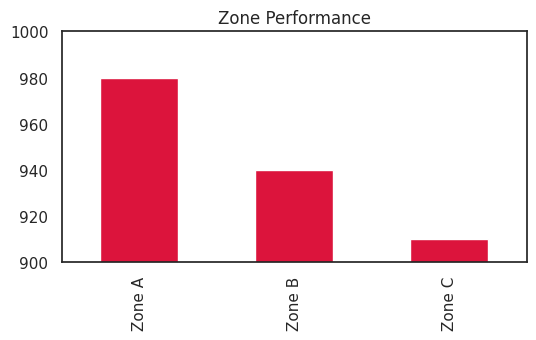

In [9]:
zones = pd.Series({'Zone A': 980, 'Zone B': 940, 'Zone C': 910})
fig, ax = plt.subplots(figsize=(6, 3))
zones.plot(kind='bar', color='crimson', ax=ax)
ax.set_ylim(900, 1000)
ax.set_title('Zone Performance')
plt.show()

FAIL - title states a finding
FAIL - axes labeled with units
PASS - right chart for the question
FAIL - honest scale
PASS - readable
PASS - no wasted ink

score: 3/6


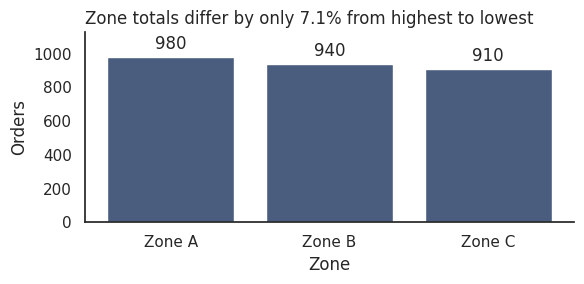

The gap is 70 orders (7.1% of the highest zone). That looks modest; whether it matters operationally depends on staffing needs and the cost of covering the difference.


In [10]:
score(
    title=False,
    axes=False,
    chart_type=True,
    scale=False,
    readable=True,
    ink=True
)

ordered = zones.sort_values(ascending=False)
gap = ordered.max() - ordered.min()
gap_pct = gap / ordered.max() * 100

fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(ordered.index, ordered.values, color=BLUE)

finish(
    ax,
    f'Zone totals differ by only {gap_pct:.1f}% from highest to lowest',
    xlabel='Zone',
    ylabel='Orders'
)

ax.set_ylim(0, ordered.max() * 1.15)
ax.bar_label(bars, labels=[f'{value:,.0f}' for value in ordered.values], padding=3)
plt.show()

print(
    f'The gap is {gap:,.0f} orders ({gap_pct:.1f}% of the highest zone). '
    'That looks modest; whether it matters operationally depends on staffing needs '
    'and the cost of covering the difference.'
)

### Chart 3 — wrong chart type for time (Monday mistakes + Recipe 3)

Stacked bars hide when each series peaks. The staffing story lives in the *timing*.

**TODO:** score the default, then rebuild: one line per zone (or total orders), kickoff at 15.5, and a title with the staffing decision a manager should draw — same pattern as Monday's orders-by-hour example.

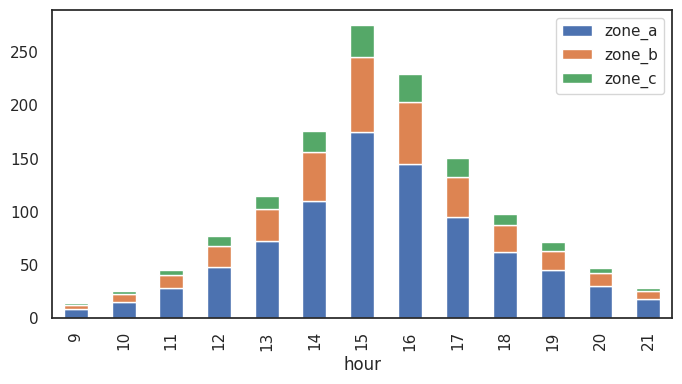

In [11]:
hourly = pd.DataFrame({
    'hour': list(range(9, 22)),
    'zone_a': [8, 15, 28, 48, 72, 110, 175, 145, 95, 62, 45, 30, 18],
    'zone_b': [4, 7, 12, 20, 30, 46, 70, 58, 38, 25, 18, 12, 7],
    'zone_c': [2, 3, 5, 9, 13, 20, 31, 26, 17, 11, 8, 5, 3],
}).set_index('hour')

fig, ax = plt.subplots(figsize=(8, 4))
hourly.plot(kind='bar', stacked=True, ax=ax)
plt.show()

FAIL - title states a finding
FAIL - axes labeled with units
FAIL - right chart for the question
PASS - honest scale
FAIL - readable
PASS - no wasted ink

score: 2/6


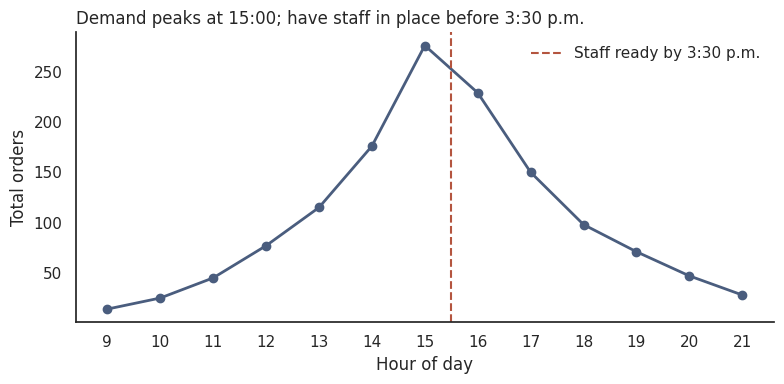

In [12]:
score(
    title=False,
    axes=False,
    chart_type=False,
    scale=True,
    readable=False,
    ink=True
)

total_orders = hourly.sum(axis=1)
peak_hour = int(total_orders.idxmax())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    total_orders.index,
    total_orders.values,
    color=BLUE,
    marker='o',
    linewidth=2
)
ax.axvline(
    15.5,
    color=RUST,
    linestyle='--',
    label='Staff ready by 3:30 p.m.'
)

finish(
    ax,
    f'Demand peaks at {peak_hour}:00; have staff in place before 3:30 p.m.',
    xlabel='Hour of day',
    ylabel='Total orders'
)

ax.set_xticks(total_orders.index)
ax.legend(frameon=False)
plt.show()

### Your own work

Midterm presentations are still on people's minds. Open your **midterm notebook** (or Monday's cookbook if you are not happy with any midterm chart yet). Pick one chart, score it, and do **one** iteration: mechanics or sharper claim.

If it already scores 6, take your strongest chart and try to make the title more specific — compute the number in the title from the same data you plot.

Before redesign:
FAIL - title states a finding
FAIL - axes labeled with units
FAIL - right chart for the question
PASS - honest scale
FAIL - readable
PASS - no wasted ink

score: 2/6


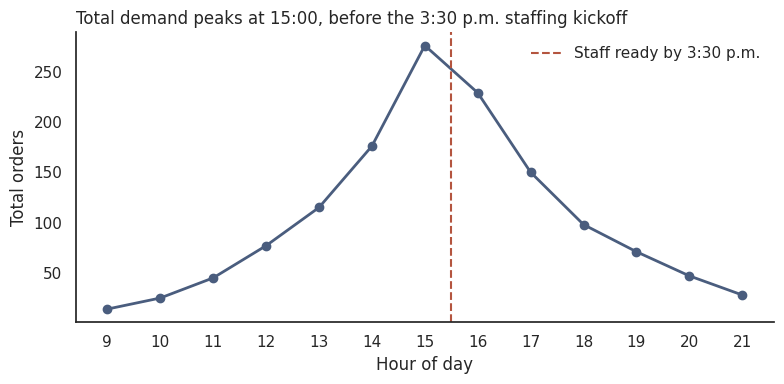

After redesign:
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [13]:
# Before: score the stacked hourly chart from Cell 19.
print('Before redesign:')
score(
    title=False,
    axes=False,
    chart_type=False,
    scale=True,
    readable=False,
    ink=True
)

# Redesign: show total orders over time to make the staffing peak easier to see.
total_orders = hourly.sum(axis=1)
peak_hour = int(total_orders.idxmax())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    total_orders.index,
    total_orders.values,
    color=BLUE,
    marker='o',
    linewidth=2
)
ax.axvline(
    15.5,
    color=RUST,
    linestyle='--',
    label='Staff ready by 3:30 p.m.'
)

finish(
    ax,
    f'Total demand peaks at {peak_hour}:00, before the 3:30 p.m. staffing kickoff',
    xlabel='Hour of day',
    ylabel='Total orders'
)

ax.set_xticks(total_orders.index)
ax.legend(frameon=False)
plt.show()

print('After redesign:')
score(
    title=True,
    axes=True,
    chart_type=True,
    scale=True,
    readable=True,
    ink=True
)

**My score before:** 2/6  After: 6/6  What I changed: I changed the stacked bars to a line chart of total orders by hour, labeled the axes with units, and added a staffing kickoff marker. The chart makes the demand peak and timing easier to read, though it no longer shows how orders differ by zone.

---

## Checkpoint (participation)

Report the rubric score of your own chart before and after your redesign, and what you changed (midterm chart or Monday cookbook chart).

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot) into this week's **Studio Checkpoint** in Canvas by **Wednesday, November 18, 11:59pm ET** — same deadline as Lab 11. One submission per person, not per group.

In [14]:
chart_i_fixed = 'Hourly orders and staffing chart'
score_before = 2
score_after = 6
new_title = (
    f'Total demand peaks at {int(hourly.sum(axis=1).idxmax())}:00, '
    'before the 3:30 p.m. staffing kickoff'
)

print('chart:', chart_i_fixed)
print('score:', score_before, '->', score_after)
print('new title:', new_title)

chart: Hourly orders and staffing chart
score: 2 -> 6
new title: Total demand peaks at 15:00, before the 3:30 p.m. staffing kickoff
